# EDA Subgrafos Regionales

Muestreo desde los ASes mas conectados, pero filtrando por subregiones

In [1]:
# --- Configuración ---

CC_FILTER = "ar"       # código de país ISO 3166-1 alpha-2 (ej: "ar", "br", "de")

HIST_BINS = 50         # bins para el histograma de grado

# Máximo de nodos a renderizar en el grafo.
# El umbral de grado mínimo se calcula automáticamente para no superar este límite.
GRAPH_MAX_NODES = 300

## Carga del grafo anotado

In [2]:
import networkx as nx

G = nx.Graph()   # or nx.DiGraph() if edges are directed

with open("../fetch/topology-202504-month-FULL.annotated.txt", "r") as f:
    for line in f:
        parts = line.strip().split()

        # unpack columns
        n1, n2, cc1, rir1, cc2, rir2 = parts

        # strip leading zeros
        n1 = str(int(n1))
        n2 = str(int(n2))

        # add/update nodes with attributes
        G.add_node(n1, cc=cc1, rir=rir1)
        G.add_node(n2, cc=cc2, rir=rir2)

        # add edge
        G.add_edge(n1, n2)

print(G.number_of_nodes(), "nodes")
print(G.number_of_edges(), "edges")

85075 nodes
706505 edges


In [3]:
# Chequeo básico
print(f"El grafo cargado de Internet es conexo: {nx.is_connected(G)}")

El grafo cargado de Internet es conexo: True


## Sub-grafo para ciertos paises

Filtro el grafo por ciertos codigos de pais o por rir.

In [4]:
cc_nodes = [n for n, attrs in G.nodes(data=True)
            if attrs.get("cc") == CC_FILTER]
G_cc = G.subgraph(cc_nodes).copy()

print(f"Subgrafo {CC_FILTER.upper()}: {G_cc.number_of_nodes():,} nodos, {G_cc.number_of_edges():,} aristas")

Subgrafo AR: 1,055 nodos, 1,927 aristas


Chequeo de conectividad del grafo:

In [5]:
print(f"El grafo cargado de Internet es conexo: {nx.is_connected(G_cc)}")

El grafo cargado de Internet es conexo: False


## Visualizando los subgrafos

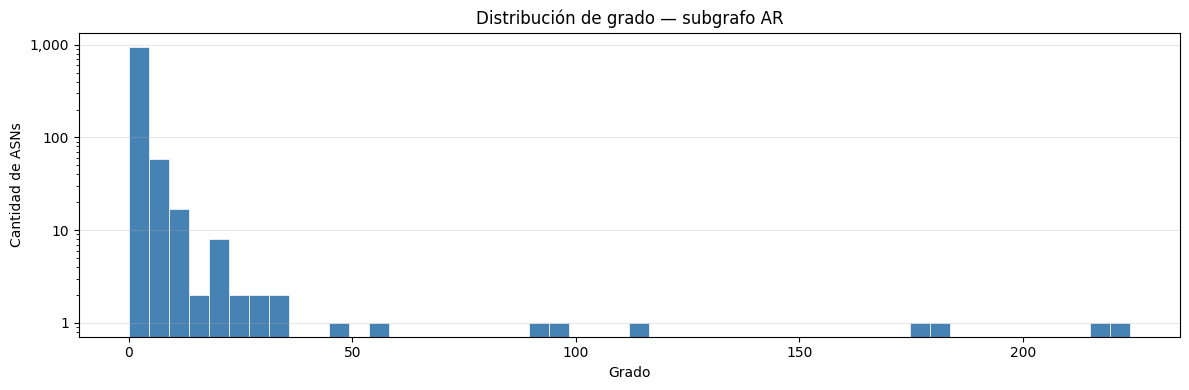

In [6]:
import numpy as np
import matplotlib.pyplot as plt

degrees = np.array(sorted(d for _, d in G_cc.degree()))

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(degrees, bins=HIST_BINS, color="steelblue", edgecolor="white", linewidth=0.5)
ax.set_yscale("log")
ax.set_title(f"Distribución de grado — subgrafo {CC_FILTER.upper()}")
ax.set_xlabel("Grado")
ax.set_ylabel("Cantidad de ASNs")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

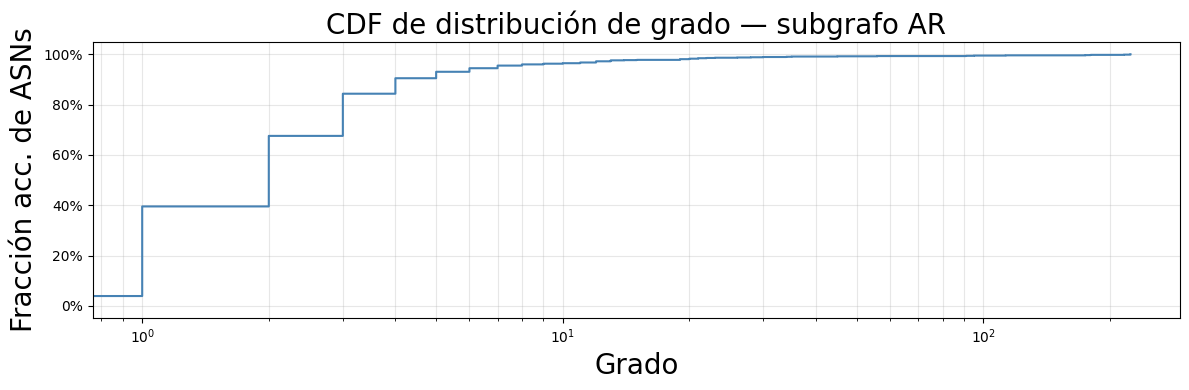

Nodos: 1,055  |  min: 0  max: 224  mean: 3.7  median: 2


In [7]:
n = len(degrees)
ecdf_y = np.arange(1, n + 1) / n

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(degrees, ecdf_y, color="steelblue", linewidth=1.5, drawstyle="steps-post")
ax.set_xscale("log")
ax.set_title(f"CDF de distribución de grado — subgrafo {CC_FILTER.upper()}", fontsize=20)
ax.set_xlabel("Grado", fontsize=20)
ax.set_ylabel("Fracción acc. de ASNs", fontsize=20)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

print(f"Nodos: {n:,}  |  min: {degrees.min()}  max: {degrees.max():,}  "
      f"mean: {degrees.mean():.1f}  median: {int(np.median(degrees))}")

### Core del grafo

Se seleccionan los `GRAPH_MAX_NODES` nodos de mayor grado. El umbral de grado mínimo se calcula automáticamente a partir de ese límite.

Umbral de grado: 3  →  342 nodos, 973 aristas


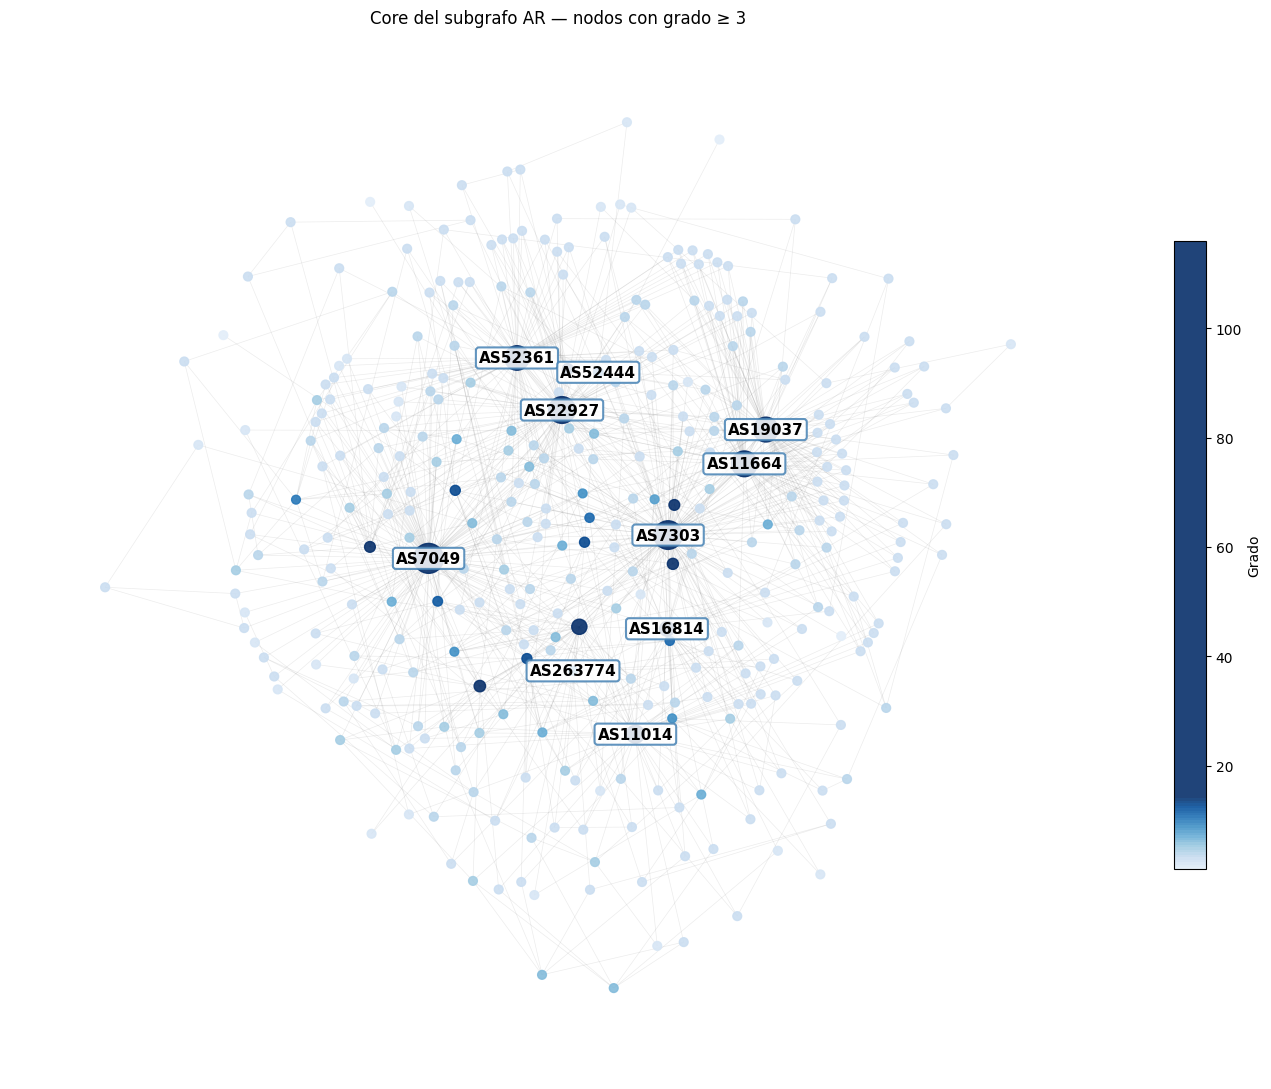

In [8]:
import scipy
from matplotlib.colors import LinearSegmentedColormap

# Calcular umbral de grado dinámicamente
ranked = sorted(G_cc.degree(), key=lambda x: x[1], reverse=True)
cutoff = ranked[min(GRAPH_MAX_NODES, len(ranked)) - 1][1]
core_nodes = [n for n, d in G_cc.degree() if d >= cutoff]
G_core = G_cc.subgraph(core_nodes).copy()

print(f"Umbral de grado: {cutoff}  →  {G_core.number_of_nodes()} nodos, {G_core.number_of_edges()} aristas")

# Layout
pos = nx.kamada_kawai_layout(G_core)

node_deg = dict(G_core.degree())
sizes  = [max(40, node_deg[n] * 4) for n in G_core.nodes()]
colors = [node_deg[n] for n in G_core.nodes()]

# Clip Blues to [0.3, 1.0] so low-degree nodes are mid-blue, not near-white
blues_clipped = LinearSegmentedColormap.from_list(
    "", plt.cm.Blues(np.linspace(0.1, 8.0, 256))
)

fig, ax = plt.subplots(figsize=(14, 11))
nx.draw_networkx_edges(G_core, pos, ax=ax, alpha=0.15, width=0.5, edge_color="gray")
nc = nx.draw_networkx_nodes(G_core, pos, ax=ax,
                             node_size=sizes, node_color=colors,
                             cmap=blues_clipped, alpha=0.9)

# White bbox anchors each label unambiguously to its node
top10 = [n for n, _ in ranked[:10] if n in G_core]
nx.draw_networkx_labels(G_core, pos, labels={n: f"AS{n}" for n in top10},
                        ax=ax, font_size=11, font_weight="bold", font_color="black",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="steelblue",
                                  alpha=0.85, linewidth=1.5))

plt.colorbar(nc, ax=ax, label="Grado", shrink=0.6)
ax.set_title(f"Core del subgrafo {CC_FILTER.upper()} — nodos con grado ≥ {cutoff}")
ax.axis("off")
plt.tight_layout()
plt.show()